# Unit 3 – Flight Delay Analysis Using Clustering and Dimensionality Reduction

**Project:** Machine Learning-Based Flight Delay Prediction and Analysis  
**Unit 3 topics:** K-Means, Gaussian Mixture Models (GMM), Expectation-Maximization (EM), Factor Analysis, PCA, dissimilarity measures, clustering evaluation and Hierarchical Clustering.

> Implementations use basic Python, NumPy and Pandas. No ready-made machine-learning estimators (such as scikit-learn) are used. Because the flight dataset is large, clustering and hierarchical clustering use reproducible samples for practical execution.

## 1. Aim and objectives

**Aim:** Discover groups of flights with similar operational characteristics and study the latent structure of flight data.

**Objectives:**
- Apply K-Means and evaluate clusters.
- Implement a diagonal-covariance GMM using the EM algorithm.
- Understand EM through its E-step and M-step.
- Apply PCA and choose the number of latent dimensions using explained variance.
- Perform a basic Factor Analysis.
- Measure dissimilarity and perform hierarchical clustering.

## 2. Mathematical models

### K-Means
Given observations $x_i$ and $K$ clusters, minimise
\[J=\sum_{k=1}^{K}\sum_{x_i\in C_k}\|x_i-\mu_k\|_2^2.\]
Assign each point to its nearest centroid, then update each centroid to the mean of its assigned points.

### Gaussian Mixture Model
\[p(x_i)=\sum_{k=1}^{K}\pi_k\mathcal{N}(x_i\mid\mu_k,\Sigma_k).\]
The E-step computes responsibilities; the M-step updates mixture weights, means and covariance matrices.

### PCA
For centred data covariance $S=X^TX/(n-1)$, eigenvectors of $S$ define principal directions. Retain the smallest number of components whose cumulative explained variance reaches the selected threshold (normally 90% or 95%).

### Factor Analysis
\[x=\Lambda f+\epsilon,\qquad Cov(x)=\Lambda\Lambda^T+\Psi,\]
where $f$ represents latent factors, $\Lambda$ is the loading matrix and $\Psi$ is diagonal unique variance.

### Hierarchical clustering
Agglomerative clustering starts with each point as a singleton cluster and repeatedly merges the closest pair according to a linkage rule.

## 3. Import libraries and load the dataset

Attach the same `flights.csv` dataset in Kaggle using **Add Data**. The cell searches for the file automatically.

In [3]:
import os, glob, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

files = glob.glob('/kaggle/input/**/flights.csv', recursive=True)
if not files:
    raise FileNotFoundError("flights.csv not found. In Kaggle, click Add Data and attach your flight dataset.")
FLIGHTS_PATH = files[0]
print("Using:", FLIGHTS_PATH)

cols = ["MONTH", "DAY", "DAY_OF_WEEK", "SCHEDULED_DEPARTURE", "DISTANCE", "ARRIVAL_DELAY"]
df = pd.read_csv(FLIGHTS_PATH, usecols=lambda c: c in cols, low_memory=False)
missing = [c for c in cols if c not in df.columns]
if missing:
    raise ValueError("Missing required columns: " + str(missing))
df = df.replace([np.inf, -np.inf], np.nan).dropna(subset=cols).copy()
print("Cleaned shape:", df.shape)
display(df.head())

Using: /kaggle/input/datasets/usdot/flight-delays/flights.csv
Cleaned shape: (5714008, 6)


,MONTH,DAY,DAY_OF_WEEK,SCHEDULED_DEPARTURE,DISTANCE,ARRIVAL_DELAY
0,1,1,4,5,1448,-22.0
1,1,1,4,10,2330,-9.0
2,1,1,4,20,2296,5.0
3,1,1,4,20,2342,-9.0
4,1,1,4,25,1448,-21.0


## 4. Prepare features

We use month, day, day of week, scheduled departure time, distance and arrival delay. Arrival delay is included here because this is an **exploratory clustering analysis**, not a pre-departure prediction model. Standardisation is essential because the variables have different units.

In [4]:
# Convert HHMM scheduled departure to hour and minute
hhmm = df["SCHEDULED_DEPARTURE"].astype(int)
hour = (hhmm // 100).clip(0, 23)
minute = (hhmm % 100).clip(0, 59)

work = pd.DataFrame({
    "MONTH": df["MONTH"].astype(float),
    "DAY": df["DAY"].astype(float),
    "DAY_OF_WEEK": df["DAY_OF_WEEK"].astype(float),
    "DEP_HOUR": hour.astype(float) + minute.astype(float)/60.0,
    "DISTANCE": df["DISTANCE"].astype(float),
    "ARRIVAL_DELAY": df["ARRIVAL_DELAY"].astype(float)
}).replace([np.inf, -np.inf], np.nan).dropna()

# Bound extreme delay values for stable exploratory distance calculations
work["ARRIVAL_DELAY"] = work["ARRIVAL_DELAY"].clip(-60, 300)

MAX_SAMPLE = 5000
sample = work.sample(n=min(MAX_SAMPLE, len(work)), random_state=42).reset_index(drop=True)
feature_names = list(sample.columns)
X_raw = sample.to_numpy(dtype=float)

mean = X_raw.mean(axis=0)
std = X_raw.std(axis=0)
std[std == 0] = 1.0
X = (X_raw - mean) / std

print("Sample shape:", X.shape)
print("Features:", feature_names)

Sample shape: (5000, 6)
Features: ['MONTH', 'DAY', 'DAY_OF_WEEK', 'DEP_HOUR', 'DISTANCE', 'ARRIVAL_DELAY']


## 5. Dissimilarity measures

Euclidean distance is used for K-Means and clustering. Manhattan distance is also calculated to demonstrate an alternative dissimilarity measure.

In [5]:
def euclidean(a, b):
    return np.sqrt(np.sum((a-b)**2, axis=-1))

def manhattan(a, b):
    return np.sum(np.abs(a-b), axis=-1)

print("Euclidean distance between first two rows:", euclidean(X[0], X[1]))
print("Manhattan distance between first two rows:", manhattan(X[0], X[1]))

Euclidean distance between first two rows: 2.5467641441677413
Manhattan distance between first two rows: 5.171169920971428


## 6. K-Means clustering (manual implementation)

**Algorithm:** Initialise K centroids; assign each observation to the nearest centroid; update centroids; repeat until assignments stop changing or the iteration limit is reached.

In [6]:
def kmeans(X, k=3, max_iter=100, seed=42):
    rng = np.random.default_rng(seed)
    centroids = X[rng.choice(len(X), size=k, replace=False)].copy()
    labels = np.zeros(len(X), dtype=int)

    for iteration in range(max_iter):
        distances = np.sqrt(((X[:, None, :] - centroids[None, :, :])**2).sum(axis=2))
        new_labels = distances.argmin(axis=1)
        new_centroids = centroids.copy()
        for j in range(k):
            members = X[new_labels == j]
            if len(members):
                new_centroids[j] = members.mean(axis=0)
            else:
                new_centroids[j] = X[rng.integers(0, len(X))]
        if np.array_equal(new_labels, labels) and np.allclose(new_centroids, centroids):
            labels, centroids = new_labels, new_centroids
            break
        labels, centroids = new_labels, new_centroids
    inertia = sum(((X[labels == j] - centroids[j])**2).sum() for j in range(k))
    return labels, centroids, inertia, iteration + 1

kmeans_results = {}
for k in [2, 3, 4, 5]:
    lab, cen, inertia, n_iter = kmeans(X, k=k)
    kmeans_results[k] = (lab, cen, inertia)
    print(f"K={k}: inertia={inertia:.2f}, iterations={n_iter}")

K=2: inertia=26131.24, iterations=23
K=3: inertia=23686.95, iterations=84
K=4: inertia=21408.51, iterations=34
K=5: inertia=18773.88, iterations=44


### Elbow method

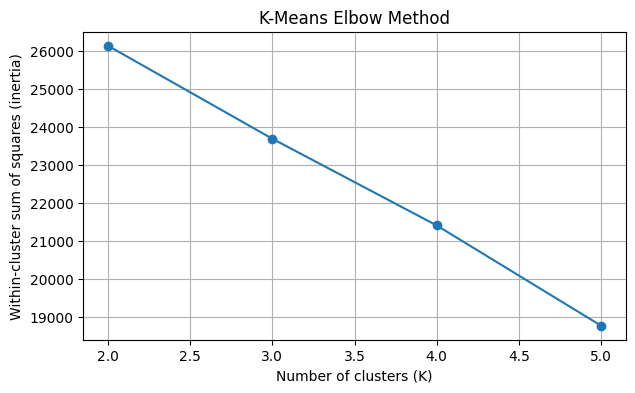

In [7]:
ks = list(kmeans_results.keys())
inertias = [kmeans_results[k][2] for k in ks]
plt.figure(figsize=(7,4))
plt.plot(ks, inertias, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Within-cluster sum of squares (inertia)")
plt.title("K-Means Elbow Method")
plt.grid(True)
plt.show()

## 7. Clustering evaluation – Silhouette coefficient

For each observation, $a(i)$ is its mean distance to points in its own cluster and $b(i)$ is the smallest mean distance to another cluster. The silhouette score is $(b(i)-a(i))/\max(a(i),b(i))$. We calculate it on a smaller random subset to keep runtime manageable.

In [8]:
def silhouette_score_manual(X, labels, max_points=700, seed=42):
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(X), size=min(max_points, len(X)), replace=False)
    A, L = X[idx], labels[idx]
    unique = np.unique(L)
    if len(unique) < 2:
        return float("nan")
    D = np.sqrt(((A[:, None, :] - A[None, :, :])**2).sum(axis=2))
    vals = []
    for i in range(len(A)):
        same = (L == L[i])
        same[i] = False
        a = D[i, same].mean() if same.sum() else 0.0
        other_means = [D[i, L == c].mean() for c in unique if c != L[i] and np.any(L == c)]
        b = min(other_means) if other_means else 0.0
        vals.append((b-a)/max(a,b) if max(a,b) > 0 else 0.0)
    return float(np.mean(vals))

for k, (lab, _, inertia) in kmeans_results.items():
    sil = silhouette_score_manual(X, lab)
    print(f"K={k}: inertia={inertia:.2f}, approximate silhouette={sil:.4f}")

K=2: inertia=26131.24, approximate silhouette=0.1284
K=3: inertia=23686.95, approximate silhouette=0.1162
K=4: inertia=21408.51, approximate silhouette=0.1335
K=5: inertia=18773.88, approximate silhouette=0.1371


## 8. Gaussian Mixture Model using EM (diagonal covariance)

The GMM represents data as a weighted sum of Gaussian distributions. The E-step calculates the probability that each point belongs to each component. The M-step updates the component parameters. Diagonal covariance is used to reduce computation and improve numerical stability.

In [9]:
def log_gaussian_diag(X, mu, var):
    var = np.maximum(var, 1e-6)
    return -0.5 * (np.sum(np.log(2*np.pi*var)) +
                   np.sum((X-mu)**2/var, axis=1))

def logsumexp(A, axis=1):
    m = np.max(A, axis=axis, keepdims=True)
    return (m + np.log(np.sum(np.exp(A-m), axis=axis, keepdims=True))).squeeze(axis)

def gmm_em(X, k=3, max_iter=100, tol=1e-4, seed=42):
    rng = np.random.default_rng(seed)
    n, d = X.shape
    mu = X[rng.choice(n, k, replace=False)].copy()
    var = np.tile(X.var(axis=0) + 1e-3, (k, 1))
    pi = np.ones(k)/k
    previous_ll = -np.inf

    for iteration in range(max_iter):
        log_joint = np.column_stack([
            np.log(pi[j] + 1e-12) + log_gaussian_diag(X, mu[j], var[j])
            for j in range(k)
        ])
        log_norm = logsumexp(log_joint, axis=1)
        resp = np.exp(log_joint - log_norm[:, None])
        Nk = resp.sum(axis=0) + 1e-10

        pi = Nk/n
        mu = (resp.T @ X) / Nk[:, None]
        for j in range(k):
            diff = X - mu[j]
            var[j] = (resp[:, j, None] * diff**2).sum(axis=0)/Nk[j] + 1e-5

        ll = log_norm.sum()
        if abs(ll-previous_ll) < tol:
            break
        previous_ll = ll

    return resp.argmax(axis=1), pi, mu, var, ll, iteration+1

gmm_labels, gmm_pi, gmm_mu, gmm_var, gmm_ll, gmm_iter = gmm_em(X, k=3)
print("GMM log-likelihood:", round(gmm_ll, 2))
print("Iterations:", gmm_iter)
print("Mixture weights:", np.round(gmm_pi, 4))
print("Cluster counts:", np.bincount(gmm_labels))
print("Approximate silhouette:", round(silhouette_score_manual(X, gmm_labels), 4))

GMM log-likelihood: -38955.36
Iterations: 77
Mixture weights: [0.2909 0.5629 0.1462]
Cluster counts: [1215 3159  626]
Approximate silhouette: 0.1597


## 9. Understanding the EM algorithm

**E-step:** Estimate hidden component memberships (responsibilities) using current parameters.

**M-step:** Re-estimate mixture weights, means and variances using those responsibilities.

These two steps repeat until the log-likelihood changes very little or the maximum number of iterations is reached.

In [10]:
# Show EM convergence concept by printing the final fitted parameters
print("Component | Weight | Mean of standardised features")
for j in range(len(gmm_pi)):
    print(j, round(gmm_pi[j], 4), np.round(gmm_mu[j], 3))

Component | Weight | Mean of standardised features
0 0.2909 [-0.026  0.016  0.042 -0.099  0.996 -0.257]
1 0.5629 [ 0.033 -0.007 -0.002 -0.049 -0.498 -0.289]
2 0.1462 [-0.075 -0.003 -0.077  0.387 -0.066  1.625]


## 10. Principal Component Analysis (PCA)

PCA transforms correlated variables into orthogonal principal components ordered by explained variance. We use the covariance matrix and its eigen-decomposition, rather than a ready-made PCA estimator.

Explained variance ratio: [0.1898 0.1713 0.1708 0.1653 0.1585 0.1443]
Cumulative explained variance: [0.1898 0.361  0.5318 0.6972 0.8557 1.    ]


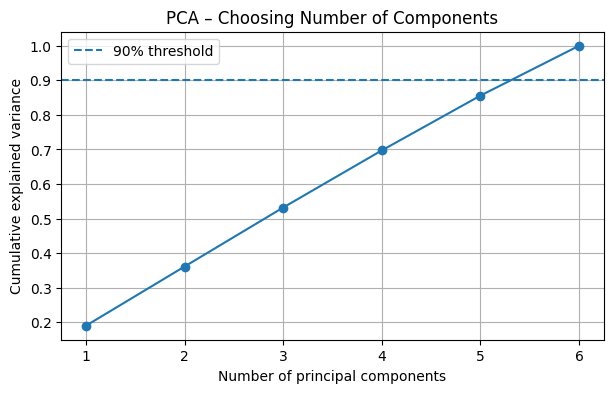

Components needed for at least 90% variance: 6
Reduced data shape: (5000, 6)


In [11]:
X_centered = X - X.mean(axis=0)
cov = np.cov(X_centered, rowvar=False)
eigvals, eigvecs = np.linalg.eigh(cov)
order = np.argsort(eigvals)[::-1]
eigvals = eigvals[order]
eigvecs = eigvecs[:, order]
explained = eigvals / eigvals.sum()
cumulative = np.cumsum(explained)

print("Explained variance ratio:", np.round(explained, 4))
print("Cumulative explained variance:", np.round(cumulative, 4))

plt.figure(figsize=(7,4))
plt.plot(range(1, len(cumulative)+1), cumulative, marker="o")
plt.axhline(0.90, linestyle="--", label="90% threshold")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA – Choosing Number of Components")
plt.legend()
plt.grid(True)
plt.show()

n90 = int(np.searchsorted(cumulative, 0.90) + 1)
print("Components needed for at least 90% variance:", n90)
X_pca = X_centered @ eigvecs[:, :n90]
print("Reduced data shape:", X_pca.shape)

## 11. Factor Analysis (principal-factor approximation)

Factor Analysis models observed variables as a combination of a small number of latent factors plus variable-specific noise. The following is a basic principal-factor extraction: it estimates communalities iteratively, then extracts factor loadings from the reduced correlation matrix. It is an educational approximation, not a full maximum-likelihood factor-analysis solver.

In [12]:
def factor_analysis_principal(X, n_factors=2, iterations=30):
    R = np.corrcoef(X, rowvar=False)
    p = R.shape[0]
    communalities = np.clip(1 - 1/np.diag(np.linalg.pinv(R)), 0.1, 0.95)

    for _ in range(iterations):
        reduced = R.copy()
        np.fill_diagonal(reduced, communalities)
        vals, vecs = np.linalg.eigh(reduced)
        idx = np.argsort(vals)[::-1][:n_factors]
        vals = np.maximum(vals[idx], 0)
        vecs = vecs[:, idx]
        loadings = vecs * np.sqrt(vals)
        new_communalities = np.clip(np.sum(loadings**2, axis=1), 0.05, 0.99)
        if np.linalg.norm(new_communalities-communalities) < 1e-5:
            communalities = new_communalities
            break
        communalities = new_communalities

    uniqueness = np.maximum(1-communalities, 1e-5)
    return loadings, communalities, uniqueness

fa_loadings, communalities, uniqueness = factor_analysis_principal(X, n_factors=2)
print("Factor loadings (rows=features, columns=factors):")
display(pd.DataFrame(fa_loadings, index=feature_names,
                     columns=["Factor 1", "Factor 2"]))
print("Communalities:", np.round(communalities, 3))
print("Unique variances:", np.round(uniqueness, 3))

Factor loadings (rows=features, columns=factors):


,Factor 1,Factor 2
MONTH,-0.028694,0.133062
DAY,-0.047205,0.030023
DAY_OF_WEEK,-0.048709,0.219218
DEP_HOUR,0.398848,0.142249
DISTANCE,-0.087992,0.047728
ARRIVAL_DELAY,0.329572,-0.111122


Communalities: [0.05  0.05  0.05  0.179 0.05  0.121]
Unique variances: [0.95  0.95  0.95  0.821 0.95  0.879]


## 12. Hierarchical clustering (agglomerative, average linkage)

To keep the pairwise-distance computation manageable, use at most 300 observations. Each point begins as its own cluster. At each iteration, merge the pair of clusters with the smallest average pairwise Euclidean distance. This implementation is intentionally straightforward for learning.

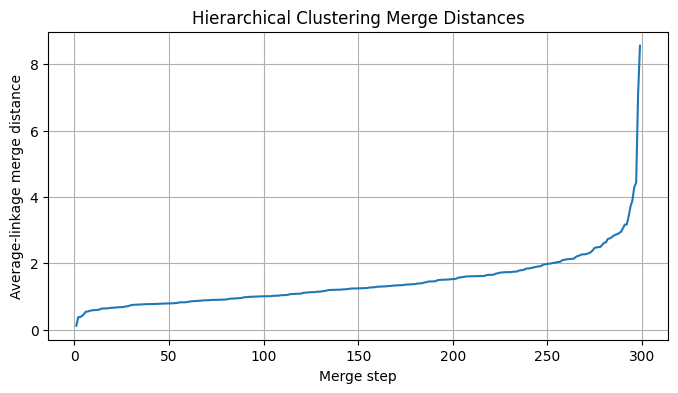

Hierarchical clustering completed on a sample of 300 rows.


In [13]:
def hierarchical_average_linkage(X, max_n=300, seed=42):
    rng = np.random.default_rng(seed)
    n = min(max_n, len(X))
    idx = rng.choice(len(X), n, replace=False)
    A = X[idx]
    D = np.sqrt(((A[:, None, :] - A[None, :, :])**2).sum(axis=2))
    clusters = [[i] for i in range(n)]
    merge_distances = []

    while len(clusters) > 1:
        best = (None, None, np.inf)
        for i in range(len(clusters)):
            for j in range(i+1, len(clusters)):
                dist = D[np.ix_(clusters[i], clusters[j])].mean()
                if dist < best[2]:
                    best = (i, j, dist)
        i, j, dist = best
        merge_distances.append(dist)
        clusters[i] = clusters[i] + clusters[j]
        clusters.pop(j)

    return merge_distances

merge_distances = hierarchical_average_linkage(X)
plt.figure(figsize=(8,4))
plt.plot(range(1, len(merge_distances)+1), merge_distances)
plt.xlabel("Merge step")
plt.ylabel("Average-linkage merge distance")
plt.title("Hierarchical Clustering Merge Distances")
plt.grid(True)
plt.show()
print("Hierarchical clustering completed on a sample of", min(300, len(X)), "rows.")

## 13. Compare clustering approaches

The K-Means and GMM labels are compared using approximate silhouette scores. A higher silhouette score generally indicates better separation, but cluster usefulness must also be interpreted using cluster profiles and domain context.

In [14]:
comparison = pd.DataFrame([
    {"Method": "K-Means (K=3)",
     "Silhouette": silhouette_score_manual(X, kmeans_results[3][0]),
     "Cluster_Count": len(np.unique(kmeans_results[3][0]))},
    {"Method": "GMM-EM (K=3)",
     "Silhouette": silhouette_score_manual(X, gmm_labels),
     "Cluster_Count": len(np.unique(gmm_labels))}
])
display(comparison)

,Method,Silhouette,Cluster_Count
0,K-Means (K=3),0.116236,3
1,GMM-EM (K=3),0.159748,3


## 14. Interpret the discovered clusters

Cluster profiles are reported in the original units to make them interpretable. These are descriptive patterns, not causal explanations.

In [15]:
km3_labels = kmeans_results[3][0]
profile_data = sample.copy()
profile_data["KMEANS_CLUSTER"] = km3_labels
print("K-Means cluster sizes:")
display(profile_data["KMEANS_CLUSTER"].value_counts().sort_index().rename("Flights"))
print("K-Means cluster profiles (original units):")
display(profile_data.groupby("KMEANS_CLUSTER")[feature_names].mean().round(2))

gmm_profile = sample.copy()
gmm_profile["GMM_CLUSTER"] = gmm_labels
print("GMM cluster profiles (original units):")
display(gmm_profile.groupby("GMM_CLUSTER")[feature_names].mean().round(2))

K-Means cluster sizes:


KMEANS_CLUSTER
0    1789
1    1532
2    1679
Name: Flights, dtype: int64

K-Means cluster profiles (original units):


,MONTH,DAY,DAY_OF_WEEK,DEP_HOUR,DISTANCE,ARRIVAL_DELAY
KMEANS_CLUSTER,,,,,,
0,6.93,16.51,5.97,13.54,887.24,-3.75
1,6.36,15.06,2.85,17.87,725.37,22.99
2,6.43,15.83,2.67,9.29,872.68,-4.77


GMM cluster profiles (original units):


,MONTH,DAY,DAY_OF_WEEK,DEP_HOUR,DISTANCE,ARRIVAL_DELAY
GMM_CLUSTER,,,,,,
0,6.53,15.92,3.99,12.94,1661.46,-6.21
1,6.67,15.81,3.90,13.25,528.58,-6.12
2,6.28,15.86,3.76,15.37,759.29,75.69


## 15. Result and conclusion

Complete this section after running all cells. Record the selected K, inertia, approximate silhouette score, GMM log-likelihood, PCA component count for 90% variance, factor loadings and hierarchical-clustering observations.

**Conclusion template:** K-Means grouped flights based on similarity in the selected operational features. GMM provided a probabilistic clustering alternative through EM. PCA reduced the feature space while retaining the chosen proportion of variance. Factor Analysis provided a latent-factor representation, and hierarchical clustering showed how observations merge at increasing dissimilarity. The best clustering method should be selected using both quantitative evaluation and meaningful cluster profiles—not inertia or accuracy alone.

## 16. Limitations

- This is exploratory unsupervised analysis; clusters are not ground-truth flight categories.
- Arrival delay is included in clustering, so clusters use outcome information. Do not describe these clusters as pre-departure predictions.
- K-Means and GMM results depend on initialisation and the selected sample.
- The GMM uses diagonal covariance for computational simplicity.
- The Factor Analysis implementation is a principal-factor educational approximation, not full maximum-likelihood factor analysis.
- Silhouette is estimated on a subset; hierarchical clustering is run on at most 300 rows.